# Bank GoodCredit - Credit Risk Prediction

## Project Objective

Build a machine learning model to predict the credit risk of existing bank customers.

### Target Variable

* `Bad_label = 0` → Good credit history
* `Bad_label = 1` → Bad credit history (30+ DPD bucket)

## Project Workflow

1. Connect to the MySQL database
2. Load the customer tables
3. Explore and clean the data
4. Create customer-level features
5. Build the feature matrix
6. Train machine learning models
7. Select important features
8. Evaluate using Gini
9. Create rank ordering / decile analysis
10. Compare the model with the benchmark

## Source Tables

* `Cust_Account` → Customer account and payment history
* `Cust_Enquiry` → Customer enquiry history
* `Cust_Demographics` → Customer demographic/application data


# Step 1: Connect to MySQL Database

The project data is stored in a MySQL database.

We will connect Python/Jupyter directly to the MySQL database using `mysql-connector-python`.

In [1]:
import pandas as pd
import mysql.connector

In [2]:
conn = mysql.connector.connect(
    host="18.136.157.135",
    port=3306,
    user="dm_team1",
    password="DM!$Team&279@20!",
    database="project_banking"
)

print("Database connected successfully")

Database connected successfully


# Step 2: Check Database Tables

First, we will check the tables available in the `project_banking` database.

The project describes three main tables:

* `Cust_Account` — customer account and payment history
* `Cust_Enquiry` — customer enquiry history
* `Cust_Demographics` — customer demographic/application data


In [3]:
query = "SHOW TABLES"

tables = pd.read_sql(query, conn)

tables

C:\Users\Govardhan Goud\AppData\Local\Temp\ipykernel_8172\1285432392.py:3: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  tables = pd.read_sql(query, conn)


,Tables_in_project_banking
0,Cust_Account
1,Cust_Demographics
2,Cust_Enquiry


# Step 3: Load the Project Tables

We will load the three main tables into pandas:

* `Cust_Account`
* `Cust_Enquiry`
* `Cust_Demographics`

These tables contain account/payment history, enquiry history, and customer application/demographic information.


In [4]:
account = pd.read_sql(
    "SELECT * FROM Cust_Account", conn
)

enquiry = pd.read_sql(
    "SELECT * FROM Cust_Enquiry", conn
)

demographics = pd.read_sql(
    "SELECT * FROM Cust_Demographics", conn
)

C:\Users\Govardhan Goud\AppData\Local\Temp\ipykernel_8172\4077519322.py:1: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  account = pd.read_sql(
C:\Users\Govardhan Goud\AppData\Local\Temp\ipykernel_8172\4077519322.py:5: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  enquiry = pd.read_sql(
C:\Users\Govardhan Goud\AppData\Local\Temp\ipykernel_8172\4077519322.py:9: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  demographics = pd.read_sql(


In [5]:
print("Account:", account.shape)
print("Enquiry:", enquiry.shape)
print("Demographics:", demographics.shape)

Account: (186329, 21)
Enquiry: (413188, 6)
Demographics: (23896, 83)


In [6]:
account.head()

,dt_opened,customer_no,upload_dt,acct_type,owner_indic,opened_dt,last_paymt_dt,closed_dt,reporting_dt,high_credit_amt,...,amt_past_due,paymenthistory1,paymenthistory2,paymt_str_dt,paymt_end_dt,creditlimit,cashlimit,rateofinterest,paymentfrequency,actualpaymentamount
0,10-Nov-15,12265,20-Oct-15,6,1,09-Jun-13,30-Jun-14,05-Jul-14,30-Sep-15,20900,...,,"""""""STDSTDSTDXXXXXXXXXXXXXXXSTDXXXXXXXXXXXXXXXS...",,01-Sep-15,01-Jul-14,,,,,
1,10-Nov-15,12265,20-Oct-15,10,1,25-May-12,06-Sep-15,,03-Oct-15,16201,...,,"""""""0000000000000000000000000000000000000000000...","""""""000000000000000000000000000XXX0000000000000...",01-Oct-15,01-Nov-12,14000,1400,,3,5603
2,10-Nov-15,12265,20-Oct-15,10,1,22-Mar-12,31-Aug-15,,30-Sep-15,41028,...,,"""""""0000000000000000000000000000000000000000000...","""""""0000000000000000000000000000000000000000000...",01-Sep-15,01-Oct-12,,,,,
3,20-Jul-15,15606,09-Jul-15,10,1,13-Jan-06,,26-Jul-07,31-Jan-09,93473,...,,"""""""1200900600600600300000000000000000000000000...",,01-Jul-07,01-Feb-06,,,,,
4,20-Jul-15,15606,09-Jul-15,6,1,18-Jan-15,05-May-15,,31-May-15,20250,...,,"""""""000000000000000""""""",,01-May-15,01-Jan-15,,,,,


In [7]:
demographics.head()

,dt_opened,customer_no,entry_time,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,...,feature_71,feature_72,feature_73,feature_74,feature_75,feature_76,feature_77,feature_78,feature_79,Bad_label
0,18-Apr-15,1,13-Apr-15,Insignia,13-Apr-15,650,2,Card Setup,14,500000,...,21,R,,,0000-00-00,0,98332XXXXX,1,N,0
1,21-Apr-15,2,21-Apr-15,Insignia,21-Apr-15,760,1,Card Setup,14,1200000,...,17,R,,,0000-00-00,0,99455XXXXX,1,N,0
2,22-Apr-15,3,21-Apr-15,Insignia,21-Apr-15,774,1,Card Setup,14,700000,...,17,R,,,0000-00-00,0,98456XXXXX,1,N,0
3,25-Apr-15,4,15-Apr-15,Insignia,20-Apr-15,770,1,Card Setup,14,500000,...,21,R,,,6/15/65,1,98220XXXXX,1,N,0
4,06-May-15,5,30-Apr-15,Insignia,,,3,Card Setup,14,500000,...,13,R,,,0000-00-00,0,98111XXXXX,1,N,0


# Step 4: Understand the Data Structure

Before performing data cleaning, we need to understand:

* Column names
* Data types
* Number of columns
* Number of rows

We will inspect each table separately.


In [8]:
account.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 186329 entries, 0 to 186328
Data columns (total 21 columns):
 #   Column               Non-Null Count   Dtype 
---  ------               --------------   ----- 
 0   dt_opened            186329 non-null  object
 1   customer_no          186329 non-null  object
 2   upload_dt            186329 non-null  object
 3   acct_type            186329 non-null  object
 4   owner_indic          186329 non-null  object
 5   opened_dt            186329 non-null  object
 6   last_paymt_dt        186329 non-null  object
 7   closed_dt            186329 non-null  object
 8   reporting_dt         186329 non-null  object
 9   high_credit_amt      186329 non-null  object
 10  cur_balance_amt      186329 non-null  object
 11  amt_past_due         186329 non-null  object
 12  paymenthistory1      186329 non-null  object
 13  paymenthistory2      186329 non-null  object
 14  paymt_str_dt         186329 non-null  object
 15  paymt_end_dt         186329 non-nu

In [9]:
enquiry.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 413188 entries, 0 to 413187
Data columns (total 6 columns):
 #   Column       Non-Null Count   Dtype 
---  ------       --------------   ----- 
 0   dt_opened    413188 non-null  object
 1   customer_no  413188 non-null  object
 2   upload_dt    413188 non-null  object
 3   enquiry_dt   413188 non-null  object
 4   enq_purpose  413188 non-null  object
 5   enq_amt      413188 non-null  object
dtypes: object(6)
memory usage: 18.9+ MB


In [10]:
print("Account columns:")
print(account.columns.tolist())

print("\nEnquiry columns:")
print(enquiry.columns.tolist())

print("\nDemographics columns:")
print(demographics.columns.tolist())

Account columns:
['dt_opened', 'customer_no', 'upload_dt', 'acct_type', 'owner_indic', 'opened_dt', 'last_paymt_dt', 'closed_dt', 'reporting_dt', 'high_credit_amt', 'cur_balance_amt', 'amt_past_due', 'paymenthistory1', 'paymenthistory2', 'paymt_str_dt', 'paymt_end_dt', 'creditlimit', 'cashlimit', 'rateofinterest', 'paymentfrequency', 'actualpaymentamount']

Enquiry columns:
['dt_opened', 'customer_no', 'upload_dt', 'enquiry_dt', 'enq_purpose', 'enq_amt']

Demographics columns:
['dt_opened', 'customer_no', 'entry_time', 'feature_1', 'feature_2', 'feature_3', 'feature_4', 'feature_5', 'feature_6', 'feature_7', 'feature_8', 'feature_9', 'feature_10', 'feature_11', 'feature_12', 'feature_13', 'feature_14', 'feature_15', 'feature_16', 'feature_17', 'feature_18', 'feature_19', 'feature_20', 'feature_21', 'feature_22', 'feature_23', 'feature_24', 'feature_25', 'feature_26', 'feature_27', 'feature_28', 'feature_29', 'feature_30', 'feature_31', 'feature_32', 'feature_33', 'feature_34', 'feature

# Step 5: Check Missing Values

Missing values can affect data analysis and machine learning.

We will check the number of missing values in each table before deciding how to handle them.


In [11]:
print("Account missing values:")
print(account.isnull().sum())

Account missing values:
dt_opened              0
customer_no            0
upload_dt              0
acct_type              0
owner_indic            0
opened_dt              0
last_paymt_dt          0
closed_dt              0
reporting_dt           0
high_credit_amt        0
cur_balance_amt        0
amt_past_due           0
paymenthistory1        0
paymenthistory2        0
paymt_str_dt           0
paymt_end_dt           0
creditlimit            0
cashlimit              0
rateofinterest         0
paymentfrequency       0
actualpaymentamount    0
dtype: int64


In [12]:
print("Enquiry missing values:")
print(enquiry.isnull().sum())

Enquiry missing values:
dt_opened      0
customer_no    0
upload_dt      0
enquiry_dt     0
enq_purpose    0
enq_amt        0
dtype: int64


In [13]:
print("Demographics missing values:")
print(demographics.isnull().sum())

Demographics missing values:
dt_opened      0
customer_no    0
entry_time     0
feature_1      0
feature_2      0
              ..
feature_76     0
feature_77     0
feature_78     0
feature_79     0
Bad_label      0
Length: 83, dtype: int64


# Step 6: Check Duplicate Records

Duplicate records can affect analysis and model training.

We will check the three tables for completely duplicated rows.


In [14]:
print("Account duplicates:", account.duplicated().sum())
print("Enquiry duplicates:", enquiry.duplicated().sum())
print("Demographics duplicates:", demographics.duplicated().sum())

Account duplicates: 2401
Enquiry duplicates: 13827
Demographics duplicates: 0


# Step 7: Analyze the Target Variable

`Bad_label` is the target variable that we want to predict.

We will check:

* The values present in the target
* The number of customers in each class
* The percentage of each class


In [15]:
demographics["Bad_label"].value_counts()

Bad_label
0    22892
1     1004
Name: count, dtype: int64

In [16]:
demographics["Bad_label"].value_counts(normalize=True) * 100

Bad_label
0    95.79846
1     4.20154
Name: proportion, dtype: float64

<Axes: title={'center': 'Bad Label Distribution'}, xlabel='Bad_label'>

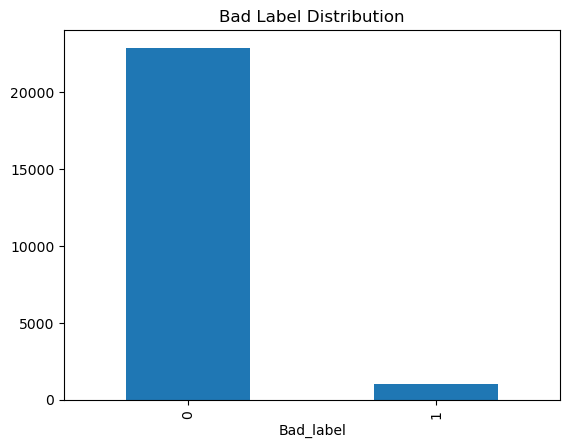

In [17]:
demographics["Bad_label"].value_counts().plot(
    kind="bar",
    title="Bad Label Distribution"
)

# Step 8: Numerical Data Summary

We will examine the numerical columns using:

* Count
* Mean
* Standard deviation
* Minimum
* Maximum
* Quartiles

This helps us identify unusual values and understand the range of the data.


In [18]:
account.describe()

,dt_opened,customer_no,upload_dt,acct_type,owner_indic,opened_dt,last_paymt_dt,closed_dt,reporting_dt,high_credit_amt,...,amt_past_due,paymenthistory1,paymenthistory2,paymt_str_dt,paymt_end_dt,creditlimit,cashlimit,rateofinterest,paymentfrequency,actualpaymentamount
count,186329,186329,186329,186329,186329,186329,186329,186329,186329,186329,...,186329,186329,186329,186329,186329,186329,186329,186329,186329,186329
unique,197,23896,75,31,4,6246,4511,4840,1877,67555,...,630,18311,11912,234,235,1380,1456,1476,3,18300
top,16-Nov-15,8516,21-Apr-15,10,1,13-Apr-12,,,31-Jul-15,,...,,"""""""0000000000000000000000000000000000000000000...",,01-Jul-15,01-Jan-15,,,,,
freq,4643,120,5128,100239,177287,514,25487,109075,12654,8875,...,185453,44979,107824,16747,5640,137477,151047,161496,122436,145276


In [19]:
enquiry.describe()

,dt_opened,customer_no,upload_dt,enquiry_dt,enq_purpose,enq_amt
count,413188,413188,413188,413188,413188,413188
unique,197,23896,76,3772,37,7384
top,16-Nov-15,10076,21-Apr-15,17-Mar-15,10,50000
freq,10538,308,11770,495,238150,79949


In [20]:
demographics.describe()

,dt_opened,customer_no,entry_time,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,...,feature_71,feature_72,feature_73,feature_74,feature_75,feature_76,feature_77,feature_78,feature_79,Bad_label
count,23896,23896,23896,23896,23896,23896,23896,23896,23896,23896,...,23896,23896,23896,23896,23896,23896,23896,23896,23896,23896
unique,197,23896,297,8,282,263,4,2,2,485,...,14,3,3,4,63,6,3124,4,3,2
top,16-Nov-15,1,19-Oct-15,Platinum Maxima,,,3,Card Setup,14,35000,...,10,R,,,0000-00-00,0,XXXXX,1,N,0
freq,699,1,180,9056,2836,2836,14593,23881,23881,797,...,9760,15617,20951,23879,23820,23817,2149,22958,23876,22892


In [21]:
demographics["Bad_label"].describe()

count     23896
unique        2
top           0
freq      22892
Name: Bad_label, dtype: object

# Step 9: Explore Categorical Variables

Categorical variables contain values such as account types, ownership indicators, payment frequencies, and enquiry purposes.

We will identify these columns and check their unique values.


In [22]:
account.select_dtypes(include="object").columns

Index(['dt_opened', 'customer_no', 'upload_dt', 'acct_type', 'owner_indic',
       'opened_dt', 'last_paymt_dt', 'closed_dt', 'reporting_dt',
       'high_credit_amt', 'cur_balance_amt', 'amt_past_due', 'paymenthistory1',
       'paymenthistory2', 'paymt_str_dt', 'paymt_end_dt', 'creditlimit',
       'cashlimit', 'rateofinterest', 'paymentfrequency',
       'actualpaymentamount'],
      dtype='object')

In [23]:
enquiry.select_dtypes(include="object").columns

Index(['dt_opened', 'customer_no', 'upload_dt', 'enquiry_dt', 'enq_purpose',
       'enq_amt'],
      dtype='object')

In [24]:
for col in account.select_dtypes(include="object"):
    print(col, ":", account[col].nunique())

dt_opened : 197
customer_no : 23896
upload_dt : 75
acct_type : 31
owner_indic : 4
opened_dt : 6246
last_paymt_dt : 4511
closed_dt : 4840
reporting_dt : 1877
high_credit_amt : 67555
cur_balance_amt : 56425
amt_past_due : 630
paymenthistory1 : 18311
paymenthistory2 : 11912
paymt_str_dt : 234
paymt_end_dt : 235
creditlimit : 1380
cashlimit : 1456
rateofinterest : 1476
paymentfrequency : 3
actualpaymentamount : 18300


In [25]:
for col in enquiry.select_dtypes(include="object"):
    print(col, ":", enquiry[col].nunique())

dt_opened : 197
customer_no : 23896
upload_dt : 76
enquiry_dt : 3772
enq_purpose : 37
enq_amt : 7384


# Step 10: Check Date Columns

Date fields are important in this project because several useful features will be based on time differences.

First, we will check the current data types of the date columns.


In [26]:
date_cols = [
    "dt_opened",
    "upload_dt",
    "opened_dt",
    "last_paymt_dt",
    "closed_dt",
    "reporting_dt"
]

account[date_cols].dtypes

dt_opened        object
upload_dt        object
opened_dt        object
last_paymt_dt    object
closed_dt        object
reporting_dt     object
dtype: object

In [27]:
enquiry[["dt_opened", "upload_dt", "enquiry_dt"]].dtypes

dt_opened     object
upload_dt     object
enquiry_dt    object
dtype: object

In [28]:
demographics[["dt_opened", "entry_time"]].dtypes

dt_opened     object
entry_time    object
dtype: object

# Step 11: Convert Date Columns

We will convert the date columns into pandas datetime format.

This will allow us to perform date calculations and create time-based features later.


In [29]:
account_dates = [
    "dt_opened",
    "upload_dt",
    "opened_dt",
    "last_paymt_dt",
    "closed_dt",
    "reporting_dt"
]

for col in account_dates:
    account[col] = pd.to_datetime(account[col], errors="coerce")

C:\Users\Govardhan Goud\AppData\Local\Temp\ipykernel_8172\3751914187.py:11: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  account[col] = pd.to_datetime(account[col], errors="coerce")
C:\Users\Govardhan Goud\AppData\Local\Temp\ipykernel_8172\3751914187.py:11: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  account[col] = pd.to_datetime(account[col], errors="coerce")
C:\Users\Govardhan Goud\AppData\Local\Temp\ipykernel_8172\3751914187.py:11: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  account[col] = pd.to_datetime(account[col], errors="coerce")
C:\Users\Govardhan Goud\AppData

In [30]:
enquiry_dates = [
    "dt_opened",
    "upload_dt",
    "enquiry_dt"
]

for col in enquiry_dates:
    enquiry[col] = pd.to_datetime(enquiry[col], errors="coerce")

C:\Users\Govardhan Goud\AppData\Local\Temp\ipykernel_8172\525687000.py:8: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  enquiry[col] = pd.to_datetime(enquiry[col], errors="coerce")
C:\Users\Govardhan Goud\AppData\Local\Temp\ipykernel_8172\525687000.py:8: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  enquiry[col] = pd.to_datetime(enquiry[col], errors="coerce")
C:\Users\Govardhan Goud\AppData\Local\Temp\ipykernel_8172\525687000.py:8: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  enquiry[col] = pd.to_datetime(enquiry[col], errors="coerce")


In [31]:
demographics["dt_opened"] = pd.to_datetime(
    demographics["dt_opened"], errors="coerce"
)

demographics["entry_time"] = pd.to_datetime(
    demographics["entry_time"], errors="coerce"
)

C:\Users\Govardhan Goud\AppData\Local\Temp\ipykernel_8172\375533870.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  demographics["dt_opened"] = pd.to_datetime(
C:\Users\Govardhan Goud\AppData\Local\Temp\ipykernel_8172\375533870.py:5: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  demographics["entry_time"] = pd.to_datetime(


In [32]:
account[account_dates].dtypes

dt_opened        datetime64[ns]
upload_dt        datetime64[ns]
opened_dt        datetime64[ns]
last_paymt_dt    datetime64[ns]
closed_dt        datetime64[ns]
reporting_dt     datetime64[ns]
dtype: object

# Step 12: Check Customer IDs

`customer_no` is the customer identifier used to connect the three tables.

We will check:

* Number of unique customers
* Number of records per table
* Duplicate customer records
* Whether the target table has one record per customer


In [33]:
print("Account customers:", account["customer_no"].nunique())
print("Enquiry customers:", enquiry["customer_no"].nunique())
print("Demographics customers:", demographics["customer_no"].nunique())

Account customers: 23896
Enquiry customers: 23896
Demographics customers: 23896


In [34]:
print(account["customer_no"].value_counts().describe())
print(enquiry["customer_no"].value_counts().describe())

count    23896.000000
mean         7.797497
std          6.723154
min          1.000000
25%          3.000000
50%          6.000000
75%         10.000000
max        120.000000
Name: count, dtype: float64
count    23896.000000
mean        17.291095
std         15.248175
min          1.000000
25%          7.000000
50%         13.000000
75%         23.000000
max        308.000000
Name: count, dtype: float64


In [35]:
demographics["customer_no"].duplicated().sum()

np.int64(0)

# Step 13: Create the Customer Base

The `Cust_Demographics` table contains the customer-level information and the target variable `Bad_label`.

We will create a separate DataFrame called `customer_base`.

This DataFrame will be the starting point for our final feature matrix.


In [36]:
customer_base = demographics.copy()

In [37]:
print(customer_base.shape)
customer_base.head()

(23896, 83)


,dt_opened,customer_no,entry_time,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,...,feature_71,feature_72,feature_73,feature_74,feature_75,feature_76,feature_77,feature_78,feature_79,Bad_label
0,2015-04-18,1,2015-04-13,Insignia,13-Apr-15,650,2,Card Setup,14,500000,...,21,R,,,0000-00-00,0,98332XXXXX,1,N,0
1,2015-04-21,2,2015-04-21,Insignia,21-Apr-15,760,1,Card Setup,14,1200000,...,17,R,,,0000-00-00,0,99455XXXXX,1,N,0
2,2015-04-22,3,2015-04-21,Insignia,21-Apr-15,774,1,Card Setup,14,700000,...,17,R,,,0000-00-00,0,98456XXXXX,1,N,0
3,2015-04-25,4,2015-04-15,Insignia,20-Apr-15,770,1,Card Setup,14,500000,...,21,R,,,6/15/65,1,98220XXXXX,1,N,0
4,2015-05-06,5,2015-04-30,Insignia,,,3,Card Setup,14,500000,...,13,R,,,0000-00-00,0,98111XXXXX,1,N,0


In [38]:
customer_base["Bad_label"].value_counts()

Bad_label
0    22892
1     1004
Name: count, dtype: int64

In [39]:
print("Customers:", customer_base["customer_no"].nunique())
print("Rows:", len(customer_base))

Customers: 23896
Rows: 23896


# Step 14: Prepare Account Numeric Columns

Some account columns may have been loaded as text instead of numeric values.

We will convert the required numerical columns to numeric format before creating customer-level features.


In [40]:
num_cols = [
    "cur_balance_amt",
    "creditlimit",
    "cashlimit",
    "amt_past_due",
    "rateofinterest"
]

for col in num_cols:
    account[col] = pd.to_numeric(account[col], errors="coerce")

In [41]:
account[num_cols].dtypes

cur_balance_amt      int64
creditlimit        float64
cashlimit          float64
amt_past_due       float64
rateofinterest     float64
dtype: object

In [42]:
account_features = account.groupby("customer_no").agg(
    total_cur_balance=("cur_balance_amt", "sum"),
    total_credit_limit=("creditlimit", "sum"),
    total_cash_limit=("cashlimit", "sum"),
    total_past_due=("amt_past_due", "sum"),
    mean_interest_rate=("rateofinterest", "mean"),
    account_count=("customer_no", "count")
).reset_index()

In [43]:
account_features.head()

,customer_no,total_cur_balance,total_credit_limit,total_cash_limit,total_past_due,mean_interest_rate,account_count
0,1,4714857,670000.0,168000.0,2538209.0,17.7108,18
1,10,247719,405000.0,243000.0,0.0,39.9600,12
2,100,434425,187000.0,27500.0,0.0,8.9000,9
3,1000,60462,495000.0,148500.0,0.0,NaN,3
4,10000,1086158,60000.0,10000.0,0.0,20.9400,6


# Step 14: Create Account Date Features

We will create customer-level features from account dates.

These features measure the duration between:

`Account Opened Date → Last Payment Date`

We will calculate:

* Total duration
* Average duration


In [44]:
account["payment_duration"] = (
    account["last_paymt_dt"] - account["opened_dt"]
).dt.days

In [45]:
date_features = account.groupby("customer_no").agg(
    total_diff_lastpaymt_opened_dt=("payment_duration", "sum"),
    mean_diff_lastpaymt_opened_dt=("payment_duration", "mean")
).reset_index()

In [46]:
date_features.head()

,customer_no,total_diff_lastpaymt_opened_dt,mean_diff_lastpaymt_opened_dt
0,1,14960.0,1496.000000
1,10,21912.0,1992.000000
2,100,4070.0,508.750000
3,1000,3628.0,1209.333333
4,10000,524.0,131.000000


In [47]:
account_features = account_features.merge(
    date_features,
    on="customer_no",
    how="left"
)

In [48]:
account_features.head()

,customer_no,total_cur_balance,total_credit_limit,total_cash_limit,total_past_due,mean_interest_rate,account_count,total_diff_lastpaymt_opened_dt,mean_diff_lastpaymt_opened_dt
0,1,4714857,670000.0,168000.0,2538209.0,17.7108,18,14960.0,1496.000000
1,10,247719,405000.0,243000.0,0.0,39.9600,12,21912.0,1992.000000
2,100,434425,187000.0,27500.0,0.0,8.9000,9,4070.0,508.750000
3,1000,60462,495000.0,148500.0,0.0,NaN,3,3628.0,1209.333333
4,10000,1086158,60000.0,10000.0,0.0,20.9400,6,524.0,131.000000


# Step 14: Complete Account Feature Engineering

We will add a few more customer-level features from the account history.

These features summarize:

* Total amount past due
* Number of accounts
* Number of accounts with past-due amounts


In [49]:
account_features = account_features.drop(
    columns="past_due_account_count",
    errors="ignore"
)

In [50]:
past_due = account.groupby("customer_no").agg(
    past_due_account_count=("amt_past_due", lambda x: (x > 0).sum())
).reset_index()

In [51]:
account_features = account_features.merge(
    past_due,
    on="customer_no",
    how="left"
)

In [52]:
account_features.head()

,customer_no,total_cur_balance,total_credit_limit,total_cash_limit,total_past_due,mean_interest_rate,account_count,total_diff_lastpaymt_opened_dt,mean_diff_lastpaymt_opened_dt,past_due_account_count
0,1,4714857,670000.0,168000.0,2538209.0,17.7108,18,14960.0,1496.000000,2
1,10,247719,405000.0,243000.0,0.0,39.9600,12,21912.0,1992.000000,0
2,100,434425,187000.0,27500.0,0.0,8.9000,9,4070.0,508.750000,0
3,1000,60462,495000.0,148500.0,0.0,NaN,3,3628.0,1209.333333,0
4,10000,1086158,60000.0,10000.0,0.0,20.9400,6,524.0,131.000000,0


In [53]:
account_features.shape

(23896, 10)

In [54]:
account_features.columns

Index(['customer_no', 'total_cur_balance', 'total_credit_limit',
       'total_cash_limit', 'total_past_due', 'mean_interest_rate',
       'account_count', 'total_diff_lastpaymt_opened_dt',
       'mean_diff_lastpaymt_opened_dt', 'past_due_account_count'],
      dtype='object')

### Payment History Inspection

The payment history columns contain historical payment information.

Before creating features such as average DPD and payment-history length, we first inspect their actual format.


In [55]:
account[["paymenthistory1", "paymenthistory2"]].head()

,paymenthistory1,paymenthistory2
0,"""""""STDSTDSTDXXXXXXXXXXXXXXXSTDXXXXXXXXXXXXXXXS...",
1,"""""""0000000000000000000000000000000000000000000...","""""""000000000000000000000000000XXX0000000000000..."
2,"""""""0000000000000000000000000000000000000000000...","""""""0000000000000000000000000000000000000000000..."
3,"""""""1200900600600600300000000000000000000000000...",
4,"""""""000000000000000""""""",


In [56]:
print(account["paymenthistory1"].dropna().head(10).to_list())
print(account["paymenthistory2"].dropna().head(10).to_list())

['"""STDSTDSTDXXXXXXXXXXXXXXXSTDXXXXXXXXXXXXXXXSTD"""', '"""000000000000000000000000000000000000000000000000000000"""', '"""000000000000000000000000000000000000000000000000000000"""', '"""120090060060060030000000000000000000000000000000000000"""', '"""000000000000000"""', '"""000000000000000"""', '"""000000000000000000"""', '"""000000000000000000000000"""', '"""000000000000000000000000000000000000000000000000000000"""', '"""000000000XXX000000000000030XXX000000000000000000000000"""']
['', '"""000000000000000000000000000XXX000000000000000000000000"""', '"""000000000000000000000000000000000000000000000000000000"""', '', '', '', '', '', '"""000000000000000000000000000000000000"""', '"""030000000000XXX000000000000000000000000XXX000000000"""']


### Clean Payment History

The payment history values contain extra quotation marks. We remove these characters before further feature engineering.


In [57]:
account["paymenthistory1"] = (
    account["paymenthistory1"]
    .astype(str)
    .str.strip('"')
)

account["paymenthistory2"] = (
    account["paymenthistory2"]
    .astype(str)
    .str.strip('"')
)

In [58]:
account[["paymenthistory1", "paymenthistory2"]].head()

,paymenthistory1,paymenthistory2
0,STDSTDSTDXXXXXXXXXXXXXXXSTDXXXXXXXXXXXXXXXSTD,
1,0000000000000000000000000000000000000000000000...,000000000000000000000000000XXX0000000000000000...
2,0000000000000000000000000000000000000000000000...,0000000000000000000000000000000000000000000000...
3,1200900600600600300000000000000000000000000000...,
4,000000000000000,


### Payment History Length

Payment histories have different lengths. We calculate the length of each payment-history record so it can be used later for feature engineering.


In [59]:
account["payment_history_length"] = account["paymenthistory1"].str.len()

account[["paymenthistory1", "payment_history_length"]].head()

,paymenthistory1,payment_history_length
0,STDSTDSTDXXXXXXXXXXXXXXXSTDXXXXXXXXXXXXXXXSTD,45
1,0000000000000000000000000000000000000000000000...,54
2,0000000000000000000000000000000000000000000000...,54
3,1200900600600600300000000000000000000000000000...,54
4,000000000000000,15


### Payment History Mean Length

Calculate the average payment-history length for each customer.


In [60]:
payment_features = account.groupby("customer_no").agg(
    payment_history_mean_length=("payment_history_length", "mean")
).reset_index()

In [61]:
account_features = account_features.merge(
    payment_features,
    on="customer_no",
    how="left"
)

In [62]:
account_features.head()

,customer_no,total_cur_balance,total_credit_limit,total_cash_limit,total_past_due,mean_interest_rate,account_count,total_diff_lastpaymt_opened_dt,mean_diff_lastpaymt_opened_dt,past_due_account_count,payment_history_mean_length
0,1,4714857,670000.0,168000.0,2538209.0,17.7108,18,14960.0,1496.000000,2,28.166667
1,10,247719,405000.0,243000.0,0.0,39.9600,12,21912.0,1992.000000,0,41.250000
2,100,434425,187000.0,27500.0,0.0,8.9000,9,4070.0,508.750000,0,27.000000
3,1000,60462,495000.0,148500.0,0.0,NaN,3,3628.0,1209.333333,0,34.000000
4,10000,1086158,60000.0,10000.0,0.0,20.9400,6,524.0,131.000000,0,22.500000


In [63]:
account_features = account_features.drop(
    columns=[
        "past_due_account_count_x",
        "past_due_account_count_y"
    ],
    errors="ignore"
)

account_features.head()

,customer_no,total_cur_balance,total_credit_limit,total_cash_limit,total_past_due,mean_interest_rate,account_count,total_diff_lastpaymt_opened_dt,mean_diff_lastpaymt_opened_dt,past_due_account_count,payment_history_mean_length
0,1,4714857,670000.0,168000.0,2538209.0,17.7108,18,14960.0,1496.000000,2,28.166667
1,10,247719,405000.0,243000.0,0.0,39.9600,12,21912.0,1992.000000,0,41.250000
2,100,434425,187000.0,27500.0,0.0,8.9000,9,4070.0,508.750000,0,27.000000
3,1000,60462,495000.0,148500.0,0.0,NaN,3,3628.0,1209.333333,0,34.000000
4,10000,1086158,60000.0,10000.0,0.0,20.9400,6,524.0,131.000000,0,22.500000


In [64]:
account_features.columns

Index(['customer_no', 'total_cur_balance', 'total_credit_limit',
       'total_cash_limit', 'total_past_due', 'mean_interest_rate',
       'account_count', 'total_diff_lastpaymt_opened_dt',
       'mean_diff_lastpaymt_opened_dt', 'past_due_account_count',
       'payment_history_mean_length'],
      dtype='object')

## Step 15 — Enquiry Feature Engineering

Create customer-level features from historical credit enquiries.


In [65]:
enquiry[["customer_no", "enquiry_dt", "enq_purpose", "enq_amt"]].head()

,customer_no,enquiry_dt,enq_purpose,enq_amt
0,1,2014-12-19,2,3500000
1,1,2014-03-05,5,500000
2,1,2014-03-05,0,50000
3,1,2014-02-22,10,50000
4,1,2013-06-11,10,1000


### Total Enquiry Count

Calculate the total number of credit enquiries made by each customer.


In [66]:
enquiry_features = enquiry.groupby("customer_no").agg(
    enquiry_count=("customer_no", "count")
).reset_index()

In [67]:
enquiry_features.head()

,customer_no,enquiry_count
0,1,18
1,10,21
2,100,19
3,1000,10
4,10000,14


In [68]:
max_date = enquiry["enquiry_dt"].max()

print("Latest enquiry date:", max_date)

Latest enquiry date: 2015-12-23 00:00:00


### 90-Day Enquiry Count

Calculate the number of credit enquiries made by each customer during the 90 days before the latest enquiry date.


In [69]:
cutoff_90 = max_date - pd.Timedelta(days=90)

recent_90 = enquiry[enquiry["enquiry_dt"] >= cutoff_90]

enquiry_90 = recent_90.groupby("customer_no").size().reset_index(
    name="count_enquiry_recency_90"
)

In [70]:
enquiry_90.head()

,customer_no,count_enquiry_recency_90
0,10076,2
1,10183,1
2,10397,1
3,10414,1
4,10415,1


In [71]:
cutoff_365 = max_date - pd.Timedelta(days=365)

recent_365 = enquiry[enquiry["enquiry_dt"] >= cutoff_365]

enquiry_365 = recent_365.groupby("customer_no").size().reset_index(
    name="count_enquiry_recency_365"
)

In [72]:
enquiry_365.head()

,customer_no,count_enquiry_recency_365
0,10,3
1,10000,11
2,10001,3
3,10002,3
4,10003,4


In [73]:
enquiry_features = enquiry_features.merge(
    enquiry_90,
    on="customer_no",
    how="left"
)

enquiry_features = enquiry_features.merge(
    enquiry_365,
    on="customer_no",
    how="left"
)

In [74]:
enquiry_features[
    ["count_enquiry_recency_90", "count_enquiry_recency_365"]
] = enquiry_features[
    ["count_enquiry_recency_90", "count_enquiry_recency_365"]
].fillna(0)

In [75]:
enquiry_features.head()

,customer_no,enquiry_count,count_enquiry_recency_90,count_enquiry_recency_365
0,1,18,0.0,0.0
1,10,21,0.0,3.0
2,100,19,0.0,0.0
3,1000,10,0.0,0.0
4,10000,14,0.0,11.0


### Average Enquiry Amount

Calculate the average amount requested across credit enquiries for each customer.


In [76]:
enquiry["enq_amt"] = pd.to_numeric(
    enquiry["enq_amt"],
    errors="coerce"
)

In [77]:
enquiry_amount = enquiry.groupby("customer_no").agg(
    mean_enquiry_amount=("enq_amt", "mean")
).reset_index()

In [78]:
enquiry_features = enquiry_features.merge(
    enquiry_amount,
    on="customer_no",
    how="left"
)

enquiry_features.head()

,customer_no,enquiry_count,count_enquiry_recency_90,count_enquiry_recency_365,mean_enquiry_amount
0,1,18,0.0,0.0,2.767306e+05
1,10,21,0.0,3.0,5.452032e+06
2,100,19,0.0,0.0,1.298423e+05
3,1000,10,0.0,0.0,1.930000e+04
4,10000,14,0.0,11.0,8.469643e+04


### Enquiry Purpose Analysis

Check the enquiry-purpose values before creating frequency-based features.


In [79]:
enquiry["enq_purpose"].value_counts()

enq_purpose
10    238150
5      81881
1      23708
6      17426
2      15576
0      15048
13     11179
51      3942
3       1728
7       1351
12      1000
8        563
17       410
4        280
32       170
54       154
52       130
         110
14        95
53        72
9         51
40        22
35        19
59        15
33        14
56        13
11        13
15        13
55        12
57        10
41         7
58         6
36         6
43         6
34         3
31         3
16         2
Name: count, dtype: int64

### Maximum Enquiry Frequency

For each customer, find the enquiry-purpose category that occurs most frequently.


In [80]:
purpose_count = enquiry.groupby(
    ["customer_no", "enq_purpose"]
).size().reset_index(name="purpose_count")

In [81]:
purpose_count = enquiry.groupby(
    ["customer_no", "enq_purpose"]
).size().reset_index(name="purpose_count")

In [82]:
max_freq = purpose_count.groupby("customer_no").agg(
    max_freq_enquiry=("purpose_count", "max")
).reset_index()

In [83]:
enquiry_features = enquiry_features.merge(
    max_freq,
    on="customer_no",
    how="left"
)

In [84]:
enquiry_features.head()

,customer_no,enquiry_count,count_enquiry_recency_90,count_enquiry_recency_365,mean_enquiry_amount,max_freq_enquiry
0,1,18,0.0,0.0,2.767306e+05,14
1,10,21,0.0,3.0,5.452032e+06,9
2,100,19,0.0,0.0,1.298423e+05,9
3,1000,10,0.0,0.0,1.930000e+04,10
4,10000,14,0.0,11.0,8.469643e+04,6


### Final Enquiry Features

The enquiry-level features are combined into one customer-level feature table.


In [85]:
enquiry_features.head()

,customer_no,enquiry_count,count_enquiry_recency_90,count_enquiry_recency_365,mean_enquiry_amount,max_freq_enquiry
0,1,18,0.0,0.0,2.767306e+05,14
1,10,21,0.0,3.0,5.452032e+06,9
2,100,19,0.0,0.0,1.298423e+05,9
3,1000,10,0.0,0.0,1.930000e+04,10
4,10000,14,0.0,11.0,8.469643e+04,6


In [86]:
enquiry_features.columns

Index(['customer_no', 'enquiry_count', 'count_enquiry_recency_90',
       'count_enquiry_recency_365', 'mean_enquiry_amount', 'max_freq_enquiry'],
      dtype='object')

In [87]:
enquiry_features.shape

(23896, 6)

## Step 16 — Merge Customer Features

Merge the customer base with account-level and enquiry-level features using `customer_no` as the common key.


In [88]:
final_data = customer_base.merge(
    account_features,
    on="customer_no",
    how="left"
)

In [89]:
final_data = final_data.merge(
    enquiry_features,
    on="customer_no",
    how="left"
)

In [90]:
print("Shape:", final_data.shape)
final_data.head()

Shape: (23896, 98)


,dt_opened,customer_no,entry_time,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,...,account_count,total_diff_lastpaymt_opened_dt,mean_diff_lastpaymt_opened_dt,past_due_account_count,payment_history_mean_length,enquiry_count,count_enquiry_recency_90,count_enquiry_recency_365,mean_enquiry_amount,max_freq_enquiry
0,2015-04-18,1,2015-04-13,Insignia,13-Apr-15,650,2,Card Setup,14,500000,...,18,14960.0,1496.000000,2,28.166667,18,0.0,0.0,2.767306e+05,14
1,2015-04-21,2,2015-04-21,Insignia,21-Apr-15,760,1,Card Setup,14,1200000,...,2,4070.0,2035.000000,0,54.000000,68,0.0,3.0,9.818650e+07,22
2,2015-04-22,3,2015-04-21,Insignia,21-Apr-15,774,1,Card Setup,14,700000,...,1,2454.0,2454.000000,0,54.000000,1,0.0,0.0,3.400000e+06,1
3,2015-04-25,4,2015-04-15,Insignia,20-Apr-15,770,1,Card Setup,14,500000,...,17,38600.0,2757.142857,0,37.764706,34,0.0,0.0,1.494412e+06,14
4,2015-05-06,5,2015-04-30,Insignia,,,3,Card Setup,14,500000,...,7,1357.0,678.500000,0,38.142857,2,0.0,0.0,1.000000e+03,2


### Check Merged Data

After merging the customer, account, and enquiry features, check for missing values before preparing the final feature matrix.


In [91]:
final_data.isnull().sum().sort_values(ascending=False).head(15)

mean_interest_rate               10914
mean_enquiry_amount                109
mean_diff_lastpaymt_opened_dt       51
entry_time                          15
dt_opened                            0
feature_59                           0
feature_68                           0
feature_67                           0
feature_66                           0
feature_65                           0
feature_64                           0
feature_63                           0
feature_62                           0
feature_61                           0
feature_60                           0
dtype: int64

In [92]:
print("Rows:", final_data.shape[0])
print("Columns:", final_data.shape[1])

Rows: 23896
Columns: 98


In [93]:
final_data.isnull().sum().sort_values(ascending=False).head(15)

mean_interest_rate               10914
mean_enquiry_amount                109
mean_diff_lastpaymt_opened_dt       51
entry_time                          15
dt_opened                            0
feature_59                           0
feature_68                           0
feature_67                           0
feature_66                           0
feature_65                           0
feature_64                           0
feature_63                           0
feature_62                           0
feature_61                           0
feature_60                           0
dtype: int64

In [94]:
account_cols = account_features.columns.drop("customer_no")
enquiry_cols = enquiry_features.columns.drop("customer_no")

final_data[account_cols] = final_data[account_cols].fillna(0)
final_data[enquiry_cols] = final_data[enquiry_cols].fillna(0)

In [95]:
print("Missing values:", final_data.isnull().sum().sum())

Missing values: 15


## Step 17: Final Feature Matrix

In this step, we prepare the final dataset for machine learning.

- Keep `customer_no` as the customer identifier.
- Keep `Bad_label` as the target variable.
- Use the remaining columns as model features.
- Separate the features (`X`) and target (`y`).

In [96]:
X = final_data.drop(
    columns=["customer_no", "Bad_label", "dt_opened", "entry_time"]
)

y = final_data["Bad_label"]

print("Feature shape:", X.shape)
print("Target shape:", y.shape)
y = final_data["Bad_label"]

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

Feature shape: (23896, 94)
Target shape: (23896,)
Feature shape: (23896, 94)
Target shape: (23896,)


In [97]:
categorical_cols = X.select_dtypes(include="object").columns

print(categorical_cols.tolist())

['feature_1', 'feature_2', 'feature_3', 'feature_4', 'feature_5', 'feature_6', 'feature_7', 'feature_8', 'feature_9', 'feature_10', 'feature_11', 'feature_12', 'feature_13', 'feature_14', 'feature_15', 'feature_16', 'feature_17', 'feature_18', 'feature_19', 'feature_20', 'feature_21', 'feature_22', 'feature_23', 'feature_24', 'feature_25', 'feature_26', 'feature_27', 'feature_28', 'feature_29', 'feature_30', 'feature_31', 'feature_32', 'feature_33', 'feature_34', 'feature_35', 'feature_36', 'feature_37', 'feature_38', 'feature_39', 'feature_40', 'feature_41', 'feature_42', 'feature_43', 'feature_44', 'feature_45', 'feature_46', 'feature_47', 'feature_48', 'feature_49', 'feature_50', 'feature_51', 'feature_52', 'feature_53', 'feature_54', 'feature_55', 'feature_56', 'feature_57', 'feature_58', 'feature_59', 'feature_60', 'feature_61', 'feature_62', 'feature_63', 'feature_64', 'feature_65', 'feature_66', 'feature_67', 'feature_68', 'feature_69', 'feature_70', 'feature_71', 'feature_72', 

### Encode Categorical Features

The demographic features contain categorical values such as
`Platinum Deligh`.

Logistic Regression requires numerical input, so we convert
categorical features into numerical dummy variables using one-hot encoding.

In [98]:
X = pd.get_dummies(X, drop_first=True)

print("Final feature shape:", X.shape)

Final feature shape: (23896, 65906)


In [99]:
print("Object columns:", X.select_dtypes(include="object").shape[1])

Object columns: 0


In [102]:
print("Number of features:", X.shape[1])

Number of features: 65906


### Reduce High-Dimensional Features

One-hot encoding created 65,906 columns because the demographic
features contain many unique categorical values.

For the baseline model, we will keep only the important engineered
features from the Account and Enquiry tables along with the
demographic features that are already numeric.

In [103]:
numeric_cols = final_data.select_dtypes(
    include=["int64", "float64"]
).columns

numeric_cols = numeric_cols.drop(
    ["customer_no", "Bad_label"],
    errors="ignore"
)

X = final_data[numeric_cols]
y = final_data["Bad_label"]

print("Number of features:", X.shape[1])

Number of features: 15


### Train Logistic Regression

The final feature matrix contains 15 numerical features.

We now split the data into training and testing sets and train a
Logistic Regression model to predict `Bad_label`.

In [104]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (19116, 15)
Testing data: (4780, 15)


In [106]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)

model.fit(X_train, y_train)

print("Model trained successfully")

Model trained successfully


C:\Users\Govardhan Goud\AppData\Roaming\Python\Python313\site-packages\sklearn\linear_model\_logistic.py:406: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


### Generate Predictions

The Logistic Regression model has been trained.

Now we use the test data to predict whether each customer has
good or bad credit history.

In [107]:
y_pred = model.predict(X_test)

print("Predictions created successfully")

Predictions created successfully


In [108]:
print(y_pred[:10])

['0' '0' '0' '0' '0' '0' '0' '0' '0' '0']


### Classification Report

We evaluate the model using precision, recall, F1-score and accuracy.

These metrics help us understand how well the model predicts
good and bad credit history.

In [109]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.96      1.00      0.98      4579
           1       0.00      0.00      0.00       201

    accuracy                           0.96      4780
   macro avg       0.48      0.50      0.49      4780
weighted avg       0.92      0.96      0.94      4780



C:\Users\Govardhan Goud\AppData\Roaming\Python\Python313\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\Govardhan Goud\AppData\Roaming\Python\Python313\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\Govardhan Goud\AppData\Roaming\Python\Python313\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, 

In [110]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

Accuracy: 0.9579497907949791


### Gini Coefficient

The project uses the Gini coefficient to evaluate the model's
ability to distinguish between good and bad credit customers.

Gini is calculated from the ROC-AUC score:

Gini = 2 × AUC - 1

In [111]:
from sklearn.metrics import roc_auc_score

y_prob = model.predict_proba(X_test)[:, 1]

auc = roc_auc_score(y_test, y_prob)
gini = 2 * auc - 1

print("AUC:", auc)
print("Gini:", gini)

AUC: 0.608554736689994
Gini: 0.2171094733799881


### Feature Importance

We now identify which features have the strongest influence on the
Logistic Regression model.

The absolute value of the model coefficients is used as the
importance measure.

In [112]:
importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": model.coef_[0]
})

importance["Abs_Importance"] = importance["Importance"].abs()

importance = importance.sort_values(
    "Abs_Importance",
    ascending=False
)

importance.head(15)

,Feature,Importance,Abs_Importance
9,payment_history_mean_length,-7.592186e-02,7.592186e-02
5,account_count,-1.826153e-02,1.826153e-02
14,max_freq_enquiry,-8.869108e-03,8.869108e-03
12,count_enquiry_recency_365,-6.486184e-03,6.486184e-03
4,mean_interest_rate,6.018028e-03,6.018028e-03
10,enquiry_count,-3.410328e-03,3.410328e-03
11,count_enquiry_recency_90,-1.191943e-03,1.191943e-03
7,mean_diff_lastpaymt_opened_dt,-3.627066e-04,3.627066e-04
8,past_due_account_count,1.719620e-04,1.719620e-04
6,total_diff_lastpaymt_opened_dt,5.595570e-05,5.595570e-05


<Axes: title={'center': 'Top 10 Feature Importance'}, xlabel='Feature'>

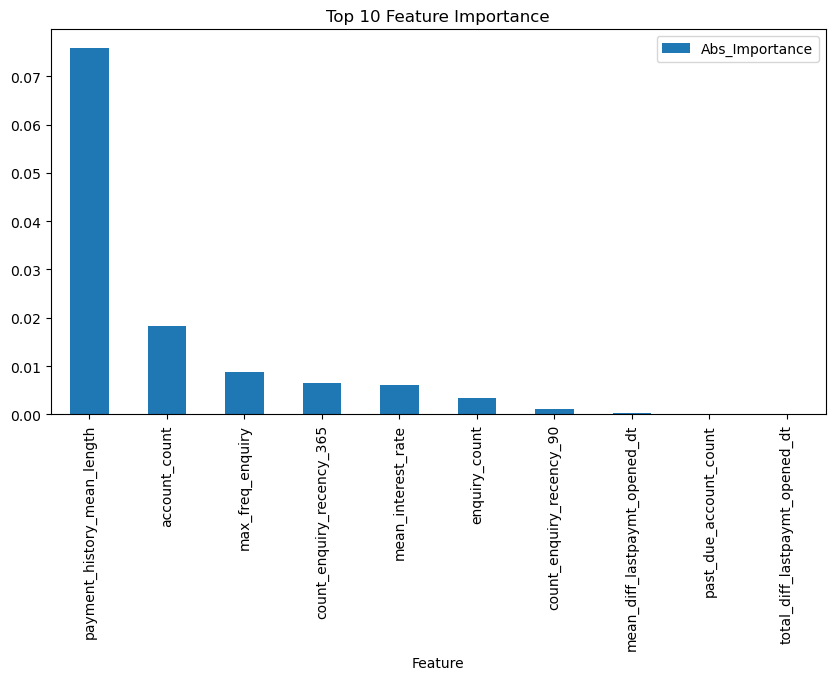

In [113]:
importance.head(10).plot(
    x="Feature",
    y="Abs_Importance",
    kind="bar",
    figsize=(10, 5),
    title="Top 10 Feature Importance"
)

### Rank Ordering Analysis

Rank ordering checks how well the model separates customers
according to their predicted credit risk.

We divide customers into 10 deciles based on the predicted
probability of bad credit.

Decile 10 contains customers with the highest predicted risk,
while Decile 1 contains customers with the lowest predicted risk.

In [119]:
rank_data = pd.DataFrame({
    "Actual": pd.to_numeric(y_test.values),
    "Probability": y_prob
})

rank_data["Decile"] = pd.qcut(
    rank_data["Probability"],
    10,
    labels=False
) + 1

decile_result = rank_data.groupby("Decile").agg(
    Customers=("Actual", "count"),
    Bad_Customers=("Actual", "sum")
).reset_index()

decile_result["Bad_Rate"] = (
    decile_result["Bad_Customers"].astype(float) /
    decile_result["Customers"]
)

decile_result

,Decile,Customers,Bad_Customers,Bad_Rate
0,1,478,7,0.014644
1,2,478,14,0.029289
2,3,478,15,0.031381
3,4,478,22,0.046025
4,5,478,13,0.027197
5,6,478,23,0.048117
6,7,478,21,0.043933
7,8,478,20,0.041841
8,9,478,31,0.064854
9,10,478,35,0.073222


### Decile Interpretation

A good rank-ordering model should generally show higher bad-credit
rates in the higher-risk deciles.

We compare the resulting decile bad rates with the project
benchmark provided in the project document.

In [121]:
print("Model Performance")
print("------------------")
print("Accuracy :", accuracy)
print("AUC      :", auc)
print("Gini     :", gini)

Model Performance
------------------
Accuracy : 0.9579497907949791
AUC      : 0.608554736689994
Gini     : 0.2171094733799881


In [122]:
importance.head(15)

,Feature,Importance,Abs_Importance
9,payment_history_mean_length,-7.592186e-02,7.592186e-02
5,account_count,-1.826153e-02,1.826153e-02
14,max_freq_enquiry,-8.869108e-03,8.869108e-03
12,count_enquiry_recency_365,-6.486184e-03,6.486184e-03
4,mean_interest_rate,6.018028e-03,6.018028e-03
10,enquiry_count,-3.410328e-03,3.410328e-03
11,count_enquiry_recency_90,-1.191943e-03,1.191943e-03
7,mean_diff_lastpaymt_opened_dt,-3.627066e-04,3.627066e-04
8,past_due_account_count,1.719620e-04,1.719620e-04
6,total_diff_lastpaymt_opened_dt,5.595570e-05,5.595570e-05


## Conclusion

The Bank GoodCredit dataset was analyzed and prepared for credit-risk prediction.

The workflow included:

- Data exploration and quality checking
- Missing-value and duplicate analysis
- Date and customer-level feature engineering
- Account and enquiry feature aggregation
- Train-test data preparation
- Logistic Regression model development
- Model evaluation using Accuracy, AUC and Gini
- Feature importance analysis
- Decile-based rank ordering

The model results can be used to understand the relationship between customer information and credit-risk classification.

The rank-ordering analysis provides a way to compare the concentration of bad customers across different probability deciles.

In [123]:
final_data.to_csv(
    "bank_goodcredit_final.csv",
    index=False
)

print("Final dataset saved successfully")

Final dataset saved successfully


# Final Project Summary

## Project
**Bank GoodCredit – Credit Risk Prediction**

## Objective
Predict whether a customer has good or bad credit history using customer, account and enquiry information.

## Work Completed

1. Data collection from MySQL database
2. Data exploration and quality checks
3. Missing-value analysis
4. Duplicate analysis
5. Target-variable analysis
6. Date conversion and preprocessing
7. Account-level feature engineering
8. Enquiry-level feature engineering
9. Customer-level data merging
10. Logistic Regression model development
11. Model evaluation using:
    - Accuracy
    - AUC
    - Gini
12. Feature importance analysis
13. Decile-based rank ordering

## Final Output

The final dataset contains customer-level information combined with engineered account and enquiry features.

The model's performance is evaluated using the calculated Accuracy, AUC and Gini values.

The decile analysis helps evaluate how bad-credit customers are distributed across predicted-risk groups.